# 04 · EDA step 3: what wins games (women's)

**Question:** inside a game, what separates the winner from the loser?

**Why this matters for the model.** None of these stats can be model inputs: they're only
known once the game is over. They tell us **which areas of play decide games**, and so
which pre-game features are worth building and testing in step 5:

- If outshooting the opponent wins games, then a team's *past* shot share is a candidate
  predictor.
- If special teams rarely decide games, power-play features drop down the list.
- If leading teams sit back and get outshot (score effects), raw shot share understates the
  better team, and a score-adjusted version should be tested.

Each section ends with **what it means for the model**.

**Setup**
- One row per **decided** game (ties dropped), from the home team's view. That's 1,068 D-I
  games from 2025-26.
- No warm-up is needed: these stats come from the game itself, not team history.
- Every stat is shown as **win % by bin**, with a 95% interval and the game count. A
  one-stat logistic regression then compares the stats on one scale.
- Only summaries are shown, never game-level rows.

In [1]:
%run ./01_pregame_features.ipynb

All leakage checks passed.


2025-26: 696 games, 41 ties
After warm-up (both teams >= 3 GP) and dropping ties: 579 games
59 diff_ features; missing values after warm-up: 1


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score


def query(conn, sql, params):
    with conn.cursor() as cur:
        cur.execute(sql, params)
        return pd.DataFrame(cur.fetchall(), columns=[d.name for d in cur.description])


EXTRA_SQL = """
SELECT t.game_id, t.team_id, t.sh_goals, t.pim, t.shots_p1, t.shots_p2, t.shots_p3
FROM hockey.team_game_stats t JOIN hockey.games g USING (game_id)
WHERE g.season = %s AND g.is_played
"""
GOALS_SQL = """
SELECT go.game_id, go.goal_number, go.team_id, go.period
FROM hockey.goals go JOIN hockey.games g USING (game_id)
WHERE g.season = %s AND g.is_played
"""
with psycopg.connect(settings.database_url) as conn:
    extra = query(conn, EXTRA_SQL, (SEASON,))
    goals = query(conn, GOALS_SQL, (SEASON,))

new_cols = ["game_id", "team_id"] + [c for c in extra.columns if c not in team_games.columns]
tg = team_games.merge(extra[new_cols], on=["game_id", "team_id"], how="left", validate="one_to_one")
goals = goals[goals["game_id"].isin(tg["game_id"])]

# Checks: the goal list matches every score, and period shots add up
n_goals = goals.groupby("game_id").size().reindex(tg["game_id"].unique(), fill_value=0)
score = tg.groupby("game_id")["goals_for"].sum()
assert (n_goals.loc[score.index] == score).all(), "goal list doesn't match a final score"
assert tg[["shots_p1", "shots_p2", "shots_p3"]].notna().all().all()
print(f"{tg['game_id'].nunique()} games, {len(goals)} goals")

696 games, 3616 goals


## Build one row per game

Every stat is from the home team's view:
- **shot_share:** home shots ÷ all shots
- **st_diff:** special teams goal differential, (home PP goals + home shorthanded goals) −
  (away PP goals + away shorthanded goals)
- **tsh_diff:** home times shorthanded − away times shorthanded
- **pim_diff:** home PIM − away PIM
- **scored_first:** whether the home team scored the first goal
- **state_p1, state_p2:** the home team was leading, tied or trailing after the 1st and
  2nd periods

In [3]:
home = tg[tg["is_home"]].set_index("game_id")
away = tg[~tg["is_home"]].set_index("game_id").loc[home.index]

first = goals.sort_values("goal_number").groupby("game_id").first()
by_period = goals.assign(
    home_goal=lambda d: d["team_id"].values == home.loc[d["game_id"], "team_id"].values
)


def margin_after(p):
    g = by_period[by_period["period"] <= p]
    m = g.groupby("game_id")["home_goal"].agg(lambda s: s.sum() - (~s).sum())
    return m.reindex(home.index, fill_value=0)


def state(m):
    return np.select([m > 0, m < 0], ["leading", "trailing"], "tied")


games = pd.DataFrame(index=home.index)
games["result"] = home["result"]
games["shot_share"] = home["shots_for"] / (home["shots_for"] + home["shots_against"])
games["st_diff"] = (home["pp_goals"] + home["sh_goals"]) - (away["pp_goals"] + away["sh_goals"])
games["tsh_diff"] = home["times_shorthanded"] - away["times_shorthanded"]
games["pim_diff"] = home["pim"] - away["pim"]
games["scored_first"] = (first.reindex(home.index)["team_id"] == home["team_id"]).map(
    {True: "scored first", False: "allowed first"}
).where(first.reindex(home.index)["team_id"].notna(), "no goals")
games["state_p1"] = state(margin_after(1))
games["state_p2"] = state(margin_after(2))

d = games[games["result"] != "T"].copy()
d["win"] = (d["result"] == "W").astype(int)
BASE = d["win"].mean()
print(f"{len(d)} decided games. Home teams won {BASE:.1%}.")

655 decided games. Home teams won 54.2%.


### Helpers

- **Wilson 95% interval** for each bin's win %.
- **Chart:** win % by bin, with the interval as a vertical line. The gray dashed line marks
  the 55% home baseline, the dotted line 50%.

In [4]:
BLUE, INK, MUTED, GRID = "#2a78d6", "#1f1f1d", "#6b6a66", "#e1e0d9"


def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


def win_by(col, bins=None, labels=None, order=None, data=None):
    data = d if data is None else data
    key = pd.cut(data[col], bins=bins, labels=labels) if bins is not None else data[col]
    t = data.groupby(key, observed=True)["win"].agg(games="size", wins="sum")
    if order is not None:
        t = t.reindex(order)
    t["win %"] = t["wins"] / t["games"]
    lo, hi = wilson(t["wins"], t["games"])
    t["95% low"], t["95% high"] = lo, hi
    t.index.name = col
    return t


def show(t, title, xlabel):
    fig, ax = plt.subplots(figsize=(7, 3.4))
    x = np.arange(len(t))
    ax.vlines(x, t["95% low"], t["95% high"], color=BLUE, lw=2, alpha=0.35)
    ax.plot(x, t["win %"], "o", color=BLUE, ms=8)
    for xi, (p, n) in enumerate(zip(t["win %"], t["games"])):
        ax.annotate(f"{p:.0%}\n{n} g", (xi, p), textcoords="offset points", xytext=(12, -8),
                    fontsize=8, color=MUTED)
    ax.axhline(BASE, color=MUTED, lw=1, ls="--")
    ax.axhline(0.5, color=MUTED, lw=0.8, ls=":")
    ax.text(-0.4, BASE + 0.01, f"home baseline {BASE:.0%}", fontsize=8, color=MUTED, va="bottom", ha="left")
    ax.set_xticks(x, [str(i) for i in t.index])
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    ax.set_ylabel("home win %", color=INK)
    ax.set_xlabel(xlabel, color=INK)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.grid(axis="y", color=GRID, lw=0.6)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    plt.tight_layout()
    plt.show()


def fmt(t):
    return t.style.format({"win %": "{:.1%}", "95% low": "{:.1%}", "95% high": "{:.1%}"})

## 1. Shot share

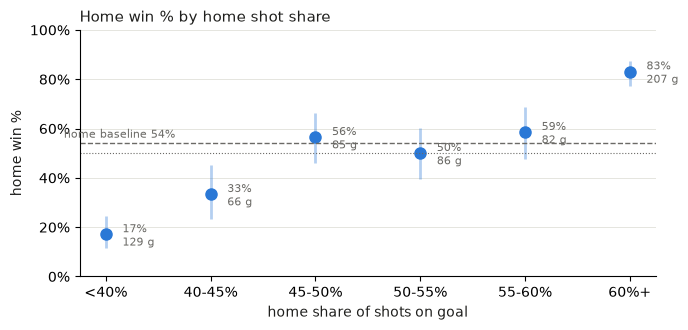

,games,wins,win %,95% low,95% high
shot_share,,,,,
<40%,129,22,17.1%,11.5%,24.5%
40-45%,66,22,33.3%,23.2%,45.3%
45-50%,85,48,56.5%,45.9%,66.5%
50-55%,86,43,50.0%,39.7%,60.3%
55-60%,82,48,58.5%,47.7%,68.6%
60%+,207,172,83.1%,77.4%,87.6%


In [5]:
SHOT_BINS = [0, 0.40, 0.45, 0.50, 0.55, 0.60, 1]
SHOT_LABELS = ["<40%", "40-45%", "45-50%", "50-55%", "55-60%", "60%+"]
t_shots = win_by("shot_share", SHOT_BINS, SHOT_LABELS)
show(t_shots, "Home win % by home shot share", "home share of shots on goal")
fmt(t_shots)

**What it means for the model:** outshooting the opponent goes with winning far more steeply
than in the men's game: from 17% with under 40% of the shots to 83% with 60% or more (men's:
35% to 68%). The middle bins overlap within their intervals. Women's D-I has wide gaps between
teams: 129 games had one side under 40% of the shots and 207 had one side over 60%.


## 2. Special teams

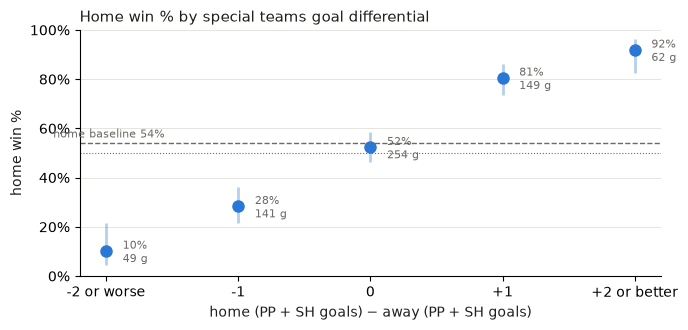

Games where special teams were even: 39%


,games,wins,win %,95% low,95% high
st_diff,,,,,
-2 or worse,49,5,10.2%,4.4%,21.8%
-1,141,40,28.4%,21.6%,36.3%
0,254,133,52.4%,46.2%,58.4%
+1,149,120,80.5%,73.4%,86.1%
+2 or better,62,57,91.9%,82.5%,96.5%


In [6]:
ST_BINS = [-99, -2, -1, 0, 1, 99]
ST_LABELS = ["-2 or worse", "-1", "0", "+1", "+2 or better"]
t_st = win_by("st_diff", ST_BINS, ST_LABELS)
show(t_st, "Home win % by special teams goal differential", "home (PP + SH goals) − away (PP + SH goals)")
print(f"Games where special teams were even: {(d['st_diff'] == 0).mean():.0%}")
fmt(t_st)

## 3. Discipline

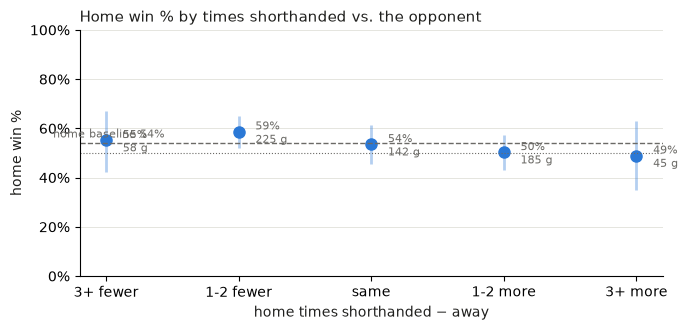

,games,wins,win %,95% low,95% high
tsh_diff,,,,,
3+ fewer,58,32,55.2%,42.5%,67.3%
1-2 fewer,225,132,58.7%,52.1%,64.9%
same,142,76,53.5%,45.3%,61.5%
1-2 more,185,93,50.3%,43.1%,57.4%
3+ more,45,22,48.9%,35.0%,63.0%


In [7]:
TSH_BINS = [-99, -3, -1, 0, 2, 99]
TSH_LABELS = ["3+ fewer", "1-2 fewer", "same", "1-2 more", "3+ more"]
t_tsh = win_by("tsh_diff", TSH_BINS, TSH_LABELS)
show(t_tsh, "Home win % by times shorthanded vs. the opponent", "home times shorthanded − away")
fmt(t_tsh)

## 4. Scoring first and leads after each period

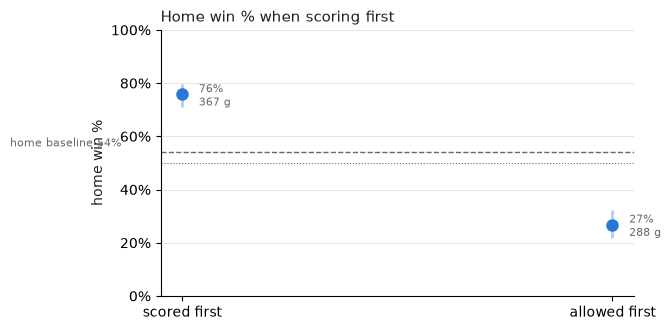

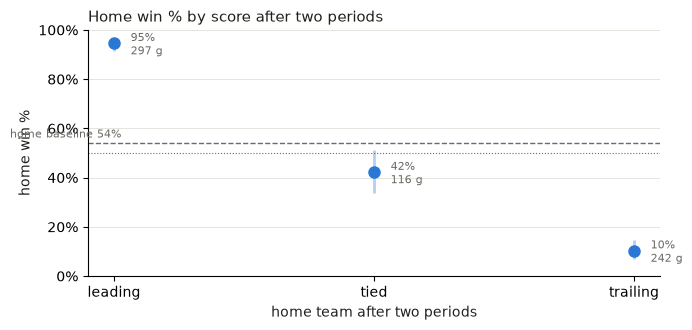

In [8]:
t_first = win_by("scored_first", order=["scored first", "allowed first"])
t_p1 = win_by("state_p1", order=["leading", "tied", "trailing"])
t_p2 = win_by("state_p2", order=["leading", "tied", "trailing"])
show(t_first, "Home win % when scoring first", "")
show(t_p2, "Home win % by score after two periods", "home team after two periods")
pd.concat({"first goal": t_first, "after 1st": t_p1, "after 2nd": t_p2}).pipe(fmt)

## 5. Score effects: do leading teams get outshot?

Compare a team's **3rd-period shot share** with its **1st and 2nd period shot share** in
the same game, split by the score after two periods. If leaders sit back, their share drops
in the 3rd and trailers' share rises.

One row per team per game here (both teams), so leading and trailing mirror each other.

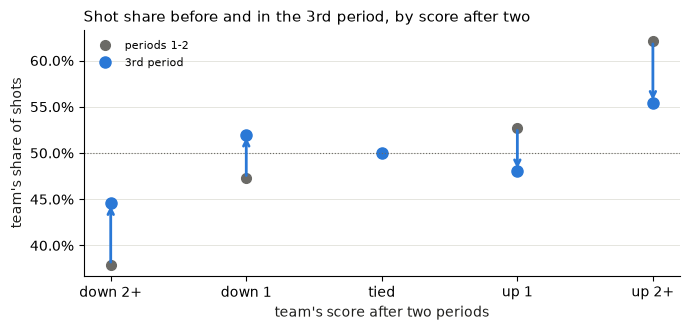

,team_games,share_p1_p2,share_p3,change
after 2nd,,,,
down 2+,338,37.9%,44.6%,+6.7%
down 1,221,47.3%,52.0%,+4.7%
tied,274,50.0%,50.0%,+0.0%
up 1,221,52.7%,48.0%,-4.7%
up 2+,338,62.1%,55.4%,-6.7%


In [9]:
tm = tg.copy()
opp = tm.set_index(["game_id", "team_id"])[["shots_p1", "shots_p2", "shots_p3"]]
o = opp.reindex(pd.MultiIndex.from_frame(tm[["game_id", "opponent_team_id"]])).to_numpy()
tm[["opp_p1", "opp_p2", "opp_p3"]] = o
tm["share_p12"] = (tm["shots_p1"] + tm["shots_p2"]) / (tm[["shots_p1", "shots_p2", "opp_p1", "opp_p2"]].sum(axis=1))
tm["share_p3"] = tm["shots_p3"] / (tm["shots_p3"] + tm["opp_p3"])

m2 = margin_after(2)
home_margin = tm["game_id"].map(m2)
tm["margin_p2"] = np.where(tm["is_home"], home_margin, -home_margin)
tm["after 2nd"] = pd.cut(tm["margin_p2"], [-99, -2, -1, 0, 1, 99],
                         labels=["down 2+", "down 1", "tied", "up 1", "up 2+"])

se = tm.groupby("after 2nd", observed=True).agg(
    team_games=("share_p3", "size"),
    share_p1_p2=("share_p12", "mean"),
    share_p3=("share_p3", "mean"),
)
se["change"] = se["share_p3"] - se["share_p1_p2"]

fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(len(se))
for xi, (a, b) in enumerate(zip(se["share_p1_p2"], se["share_p3"])):
    ax.annotate("", xy=(xi, b), xytext=(xi, a), arrowprops=dict(arrowstyle="->", color=BLUE, lw=2))
ax.plot(x, se["share_p1_p2"], "o", color=MUTED, ms=7, label="periods 1-2")
ax.plot(x, se["share_p3"], "o", color=BLUE, ms=8, label="3rd period")
ax.axhline(0.5, color=MUTED, lw=0.8, ls=":")
ax.set_xticks(x, se.index.astype(str))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_ylabel("team's share of shots", color=INK)
ax.set_xlabel("team's score after two periods", color=INK)
ax.set_title("Shot share before and in the 3rd period, by score after two", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.grid(axis="y", color=GRID, lw=0.6)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()
se.style.format({"share_p1_p2": "{:.1%}", "share_p3": "{:.1%}", "change": "{:+.1%}"})

## 6. Side by side: how strongly each stat goes with winning

Each stat gets its own logistic regression on standardized values, so the numbers are
comparable:
- **odds × per SD:** how much the odds of a home win multiply when the stat rises one
  standard deviation.
- **AUC:** how well the stat alone sorts wins from losses (0.5 = coin flip, 1.0 = perfect).
- **better side won:** in games where one team was clearly ahead on the stat, how often that
  team won.

Game-state stats (first goal, leads) are listed separately: they're part of the score
itself, so they're bound to be strong.

In [10]:
def one_stat(col, sign=1):
    x = d[[col]].astype(float).to_numpy() * sign
    z = (x - x.mean()) / x.std()
    m = LogisticRegression().fit(z, d["win"])
    p = m.predict_proba(z)[:, 1]
    edge = np.sign(x[:, 0])
    clear = edge != 0
    better_won = ((edge[clear] > 0) == (d["win"].to_numpy()[clear] == 1)).mean()
    return {"odds × per SD": np.exp(m.coef_[0][0]), "AUC": roc_auc_score(d["win"], p),
            "better side won": better_won, "games with a clear edge": int(clear.sum())}


d["shot_edge"] = d["shot_share"] - 0.5
d["first_goal"] = (games.loc[d.index, "scored_first"] == "scored first").astype(int) * 2 - 1
d["lead_p2"] = np.sign(margin_after(2).loc[d.index])

compare = pd.DataFrame({
    "shot share": one_stat("shot_edge"),
    "special teams goal diff": one_stat("st_diff"),
    "times shorthanded (fewer = better)": one_stat("tsh_diff", sign=-1),
    "PIM (fewer = better)": one_stat("pim_diff", sign=-1),
}).T
state_stats = pd.DataFrame({
    "scored first": one_stat("first_goal"),
    "led after two": one_stat("lead_p2"),
}).T
fmts = {"odds × per SD": "{:.2f}", "AUC": "{:.3f}", "better side won": "{:.1%}"}
display(compare.sort_values("AUC", ascending=False).style.format(fmts).set_caption("Play stats"))
display(state_stats.style.format(fmts).set_caption("Game-state stats (part of the score)"))

,odds × per SD,AUC,better side won,games with a clear edge
shot share,3.40,0.778,69.5%,645.000000
special teams goal diff,3.66,0.769,80.3%,401.000000
PIM (fewer = better),1.27,0.552,54.1%,532.000000
times shorthanded (fewer = better),1.15,0.541,54.4%,513.000000


,odds × per SD,AUC,better side won,games with a clear edge
scored first,2.88,0.743,74.7%,655.000000
led after two,9.07,0.911,92.4%,539.000000


In [11]:
# Do the play stats overlap? If shot share and special teams were the same signal, the model
# would only need one of them.
d[["shot_share", "st_diff", "tsh_diff", "pim_diff"]].corr().round(2)

,shot_share,st_diff,tsh_diff,pim_diff
shot_share,1.00,0.34,-0.17,-0.14
st_diff,0.34,1.00,-0.30,-0.28
tsh_diff,-0.17,-0.30,1.00,0.73
pim_diff,-0.14,-0.28,0.73,1.00


## Implications for the model

These are in-game results, so a pre-game version of each stat will predict **less**
strongly. The question for step 5 is which ones repeat (step 4).

- **Shots are the strongest play stat:** AUC 0.78 and 3.4× the odds per SD (men's: 0.64).
- **Special teams decide games too** (AUC 0.77), and overlap with shots more than in the
  men's game (r = 0.34; men's 0.19). Partly that's the score itself.
- **Discipline is weak:** PIM and times shorthanded reach AUC 0.55 and 0.54, and they overlap
  (r = 0.73).
- **Game state** (scoring first 75.7%, leading after two 92.4%) can't be used before a game.
- **Score effects are real:** teams up 2+ after two periods fall from 62.1% to 55.4% of the
  3rd-period shots, and teams down 2+ rise from 37.9% to 44.6%. Close-game shot share, which
  ignores those periods, is already a candidate.
- **Step 5 priority:** shots first, then special teams. Team strength is the reference to
  beat. Discipline and game state come last.
